# ⚡ Reworked Power Grid Demand Surge Benchmark (Daily, Weather-Onset Aligned)

### Data Sources
- **Daily Mean System Load, Forecast, Interchange & Fuel Mix:** [U.S. EIA-930 Electric Grid Monitor (`EIA930_BALANCE` 2021–2024)](https://www.eia.gov/electricity/gridmonitor/)
- **Daily Weather & Solar Irradiance (`past_future` forcing):** [NASA POWER (`MERRA-2` Reanalysis)](https://power.larc.nasa.gov/)
- **Balancing Authority Coordinates & Installed Capacity Metadata:** [Electricity Maps Zones (`EIA.gov` capacities)](https://github.com/electricitymaps/electricitymaps-contrib)

### Benchmark Design Highlights
1. **Why Daily Resolution (`[-14d, +14d]`):** Aggregating 24 hourly readings into daily means removes the strong 24-hour diurnal cycle so each heatwave or Arctic freeze cleanly shows **one single sustained surge** (flat pre-onset baseline $\rightarrow$ single surge hump $\rightarrow$ recovery).
2. **Exogenous Onset ($\tau = 0$):** Anchored strictly from NASA POWER daily mean temperature crossings into regional **heatwaves** or **Arctic freezes** (never from peak MW demand).
3. **True `past_future` Forcing:** Weather forecasts (`temp_c`, `thermal_discomfort_c`, `humidity_pct`, `solar_wm2`, `wind_ms`, `pressure_hpa`) and `day_of_week` directly drive AC/heating load.
4. **Chronological Split (`2021–2023` Train vs. `2024` Test):** `N = 286` events (`Train = 219`, `Test = 67`, `max train end 2023-12-12 < min test start 2023-12-19`, `0` NaNs).

### 1. Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

### 2. Load Full Dataset, Summary & Feature Inventory

In [2]:
npz_path = 'data/reworked_power_grid_daily.npz'
meta_path = 'data/reworked_power_grid_metadata.csv'

data = np.load(npz_path, allow_pickle=True)
meta = pd.read_csv(meta_path)

past_names = [str(x) for x in data['past_feature_names']]
pf_names = [str(x) for x in data['past_future_feature_names']]
static_names = [str(x) for x in data['static_feature_names']]
tau_steps = data['tau_steps']
date_grid = data['dates']

print(f'Samples (N):           {len(meta)}')
print(f'Days per sample (T):   {len(tau_steps)} (tau_day from {tau_steps[0]} to {tau_steps[-1]} days)')
print(f'Past covariates:       {len(past_names)} -> {past_names}')
print(f'Past-future covs:      {len(pf_names)} -> {pf_names}')
print(f'Static features:       {len(static_names)} -> {static_names}')

X_past = data['past_covariates']
X_pf = data['past_future_covariates']
X_static = data['static_features']
N, T, _ = X_past.shape

full_dict = {
    'sample_id': np.repeat(meta['sample_id'].values, T),
    'ba': np.repeat(meta['ba'].values, T),
    'region': np.repeat(meta['region'].values, T),
    'split': np.repeat(meta['split'].values, T),
    'event_type': np.repeat(meta['event_type'].values, T),
    'onset_date': np.repeat(meta['onset_date'].values, T),
    'date': date_grid.reshape(-1),
    'tau_day': np.tile(tau_steps, N),
}
for i, col in enumerate(static_names):
    full_dict[col] = np.repeat(X_static[:, i], T)
for i, col in enumerate(past_names):
    full_dict[col] = X_past[:, :, i].reshape(-1)
for i, col in enumerate(pf_names):
    full_dict[col] = X_pf[:, :, i].reshape(-1)

full_df = pd.DataFrame(full_dict)
print(f'\nFlattened full table shape: {full_df.shape}')
display(meta.head())
display(full_df[past_names + pf_names].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2))

Samples (N):           286
Days per sample (T):   29 (tau_day from -14 to 14 days)
Past covariates:       11 -> ['load_mw', 'demand_forecast_mw', 'net_gen_mw', 'load_rolling_mean_7d', 'load_change_1d', 'gas_gen_mw', 'coal_gen_mw', 'gas_share', 'solar_share', 'wind_share', 'import_share']
Past-future covs:      7 -> ['temp_c', 'apparent_temp_c', 'humidity_pct', 'solar_wm2', 'wind_ms', 'pressure_hpa', 'day_of_week']
Static features:       3 -> ['latitude', 'longitude', 'installed_cap_mw']

Flattened full table shape: (8294, 29)


,sample_id,ba,region,split,event_type,onset_date,window_start_date,window_end_date,baseline_median_mw,post_peak_mw,post_peak_tau_day,peak_surge_ratio,latitude,longitude,installed_cap_mw
0,0,PACW,NW,train,freeze,2021-01-24,2021-01-10,2021-02-07,2605.4,3080.8,2,1.182,43.1244,-121.0422,2623.4
1,1,CPLW,CAR,train,freeze,2021-01-29,2021-01-15,2021-02-12,692.7,884.3,4,1.277,35.6277,-82.5272,41.6
2,2,SC,CAR,train,freeze,2021-01-29,2021-01-15,2021-02-12,2970.6,3544.2,6,1.193,33.7029,-80.1778,5968.3
3,3,SCEG,CAR,train,freeze,2021-01-29,2021-01-15,2021-02-12,2775.4,3360.7,5,1.211,33.4102,-81.0116,8121.9
4,4,AECI,MIDW,train,freeze,2021-02-06,2021-01-23,2021-02-20,3223.4,5706.8,9,1.770,37.9740,-93.3651,6649.7


,count,mean,std,min,50%,max
load_mw,8294.0,13289.29,23455.19,176.33,2962.25,124889.79
demand_forecast_mw,8294.0,13237.52,23517.36,-91.83,2763.08,122148.66
net_gen_mw,8294.0,13100.65,23915.41,95.67,2323.88,132086.33
load_rolling_mean_7d,8294.0,13219.86,23248.95,190.46,2943.14,118080.70
load_change_1d,8294.0,15.96,1620.83,-14549.21,0.96,20614.29
gas_gen_mw,8294.0,4793.19,9666.60,-2.42,739.08,60323.79
coal_gen_mw,8294.0,2966.69,6099.44,-35.17,387.65,41004.62
gas_share,8294.0,0.34,0.27,0.00,0.31,1.00
solar_share,8294.0,0.03,0.06,0.00,0.01,0.42
wind_share,8294.0,0.07,0.12,0.00,0.00,0.72


### 3. Derived Feature Evaluation & Correlation Matrix (Justifying Redundancy Removal)

Highly correlated feature pairs (|r| > 0.90):
  - load_mw                  vs demand_forecast_mw      : r = +0.999
  - load_mw                  vs net_gen_mw              : r = +0.997
  - load_mw                  vs load_rolling_mean_7d    : r = +0.996
  - load_mw                  vs gas_gen_mw              : r = +0.969
  - load_mw                  vs coal_gen_mw             : r = +0.910
  - demand_forecast_mw       vs net_gen_mw              : r = +0.996
  - demand_forecast_mw       vs load_rolling_mean_7d    : r = +0.996
  - demand_forecast_mw       vs gas_gen_mw              : r = +0.966
  - demand_forecast_mw       vs coal_gen_mw             : r = +0.914
  - net_gen_mw               vs load_rolling_mean_7d    : r = +0.993
  - net_gen_mw               vs gas_gen_mw              : r = +0.969
  - net_gen_mw               vs coal_gen_mw             : r = +0.905
  - load_rolling_mean_7d     vs gas_gen_mw              : r = +0.962
  - load_rolling_mean_7d     vs coal_gen_mw             :

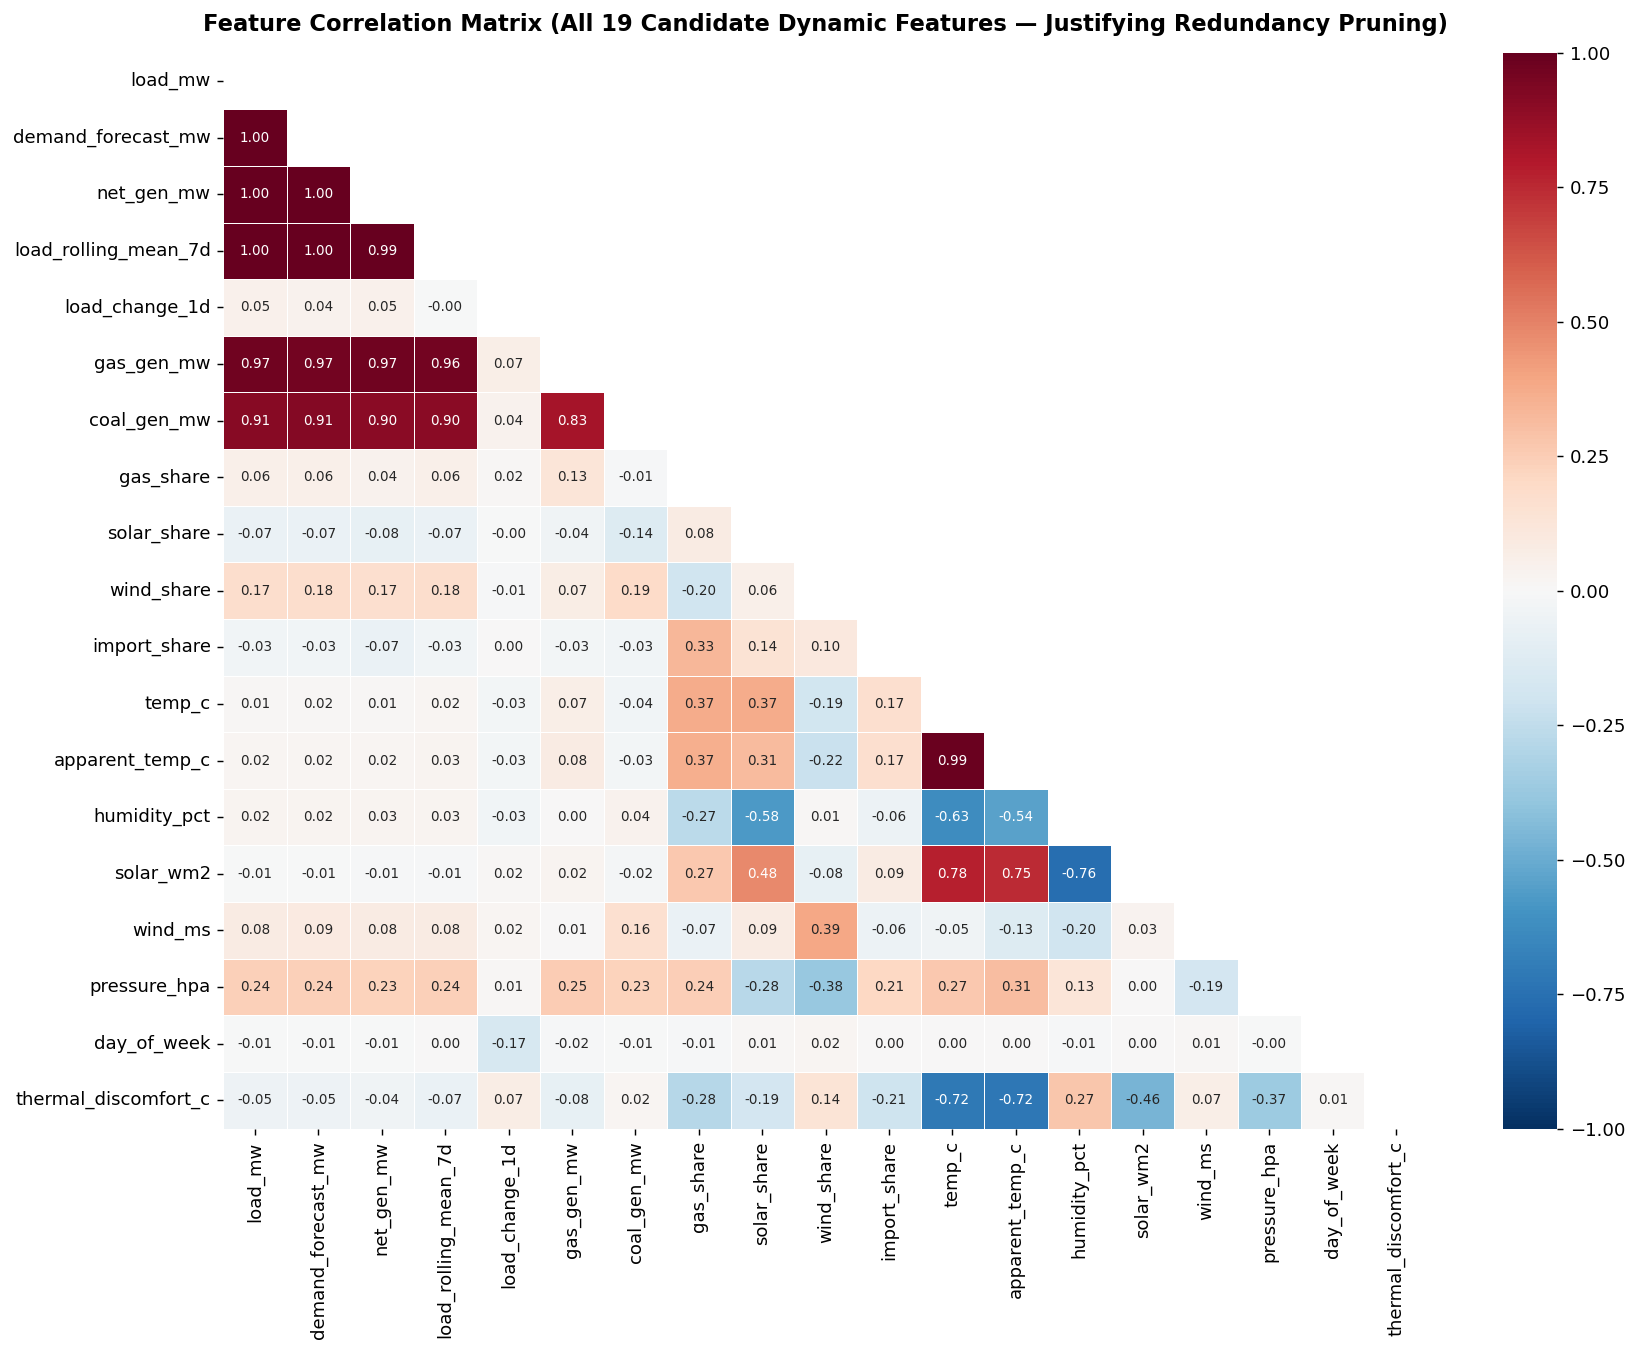

In [3]:
# Engineer V-shaped thermal discomfort index: |temp_c - 18.0| deg C
# Captures both summer AC cooling demand and winter heating demand uniformly
full_df['thermal_discomfort_c'] = np.abs(full_df['temp_c'] - 18.0)

all_candidate_features = past_names + pf_names + ['thermal_discomfort_c']
corr = full_df[all_candidate_features].corr()

print('Highly correlated feature pairs (|r| > 0.90):')
for i in range(len(all_candidate_features)):
    for j in range(i + 1, len(all_candidate_features)):
        val = corr.iloc[i, j]
        if abs(val) > 0.90:
            print(f'  - {all_candidate_features[i]:24s} vs {all_candidate_features[j]:24s}: r = {val:+.3f}')

print('\nDerived feature correlations with primary target (load_mw):')
for dcol in ['load_change_1d', 'gas_share', 'import_share', 'thermal_discomfort_c']:
    print(f'  - {dcol:24s} vs load_mw: r = {corr.loc[dcol, "load_mw"]:+.3f}')

fig, ax = plt.subplots(figsize=(13.5, 10.5), dpi=130)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    annot_kws={'size': 7.5},
    ax=ax,
)
ax.set_title(
    'Feature Correlation Matrix (All 19 Candidate Dynamic Features — Justifying Redundancy Pruning)',
    fontsize=12.5,
    fontweight='bold',
    pad=12,
)
plt.tight_layout()
plt.savefig('data/power_grid_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Create Clean Non-Redundant Simple Dataset (`data/power_grid_simple.csv`)

In [4]:
# Drop the 6 redundant scale/temperature duplicates where |r| > 0.90:
#   - demand_forecast_mw (r=+0.999 vs load_mw), net_gen_mw (r=+0.997 vs load_mw)
#   - load_rolling_mean_7d (r=+0.996 vs load_mw)
#   - gas_gen_mw (r=+0.969 vs load_mw) & coal_gen_mw (r=+0.910 vs load_mw) -> scale-invariant gas_share kept instead
#   - apparent_temp_c (r=+0.991 vs temp_c) -> keep temp_c + thermal_discomfort_c
REDUNDANT_TO_DROP = [
    'demand_forecast_mw',
    'net_gen_mw',
    'load_rolling_mean_7d',
    'gas_gen_mw',
    'coal_gen_mw',
    'apparent_temp_c',
]

KEEP_META = ['sample_id', 'ba', 'region', 'split', 'event_type', 'onset_date', 'date', 'tau_day']
KEEP_STATIC = static_names
KEEP_PAST = [c for c in past_names if c not in REDUNDANT_TO_DROP]
KEEP_PF = [c for c in pf_names + ['thermal_discomfort_c'] if c not in REDUNDANT_TO_DROP]

simple_df = full_df[KEEP_META + KEEP_STATIC + KEEP_PAST + KEEP_PF].copy()
simple_df['day_of_week'] = simple_df['day_of_week'].astype(int)

kept_dyn = KEEP_PAST + KEEP_PF
kept_corr = simple_df[kept_dyn].corr().copy()
np.fill_diagonal(kept_corr.values, 0.0)
max_r = float(kept_corr.abs().max().max())

X_std = (simple_df[kept_dyn] - simple_df[kept_dyn].mean()) / simple_df[kept_dyn].std()
vifs = dict(zip(kept_dyn, np.diag(np.linalg.inv(np.corrcoef(X_std.values, rowvar=False)))))

print(f'Dropped {len(REDUNDANT_TO_DROP)} redundant features: {REDUNDANT_TO_DROP}')
print(f'Max off-diagonal |r| among {len(kept_dyn)} kept dynamic features: {max_r:.3f}')
print(f'Max VIF across kept dynamic features: {max(vifs.values()):.2f} ({max(vifs, key=vifs.get)})')
assert simple_df.isna().sum().sum() == 0, 'Unexpected NaNs found!'

simple_csv_path = 'data/power_grid_simple.csv'
simple_df.to_csv(simple_csv_path, index=False)
print(f'Saved: {simple_csv_path} ({os.path.getsize(simple_csv_path) / (1024**2):.2f} MB), shape={simple_df.shape}')
display(simple_df.head())

Dropped 6 redundant features: ['demand_forecast_mw', 'net_gen_mw', 'load_rolling_mean_7d', 'gas_gen_mw', 'coal_gen_mw', 'apparent_temp_c']
Max off-diagonal |r| among 13 kept dynamic features: 0.780
Max VIF across kept dynamic features: 5.06 (temp_c)
Saved: data/power_grid_simple.csv (1.53 MB), shape=(8294, 24)


,sample_id,ba,region,split,event_type,onset_date,date,tau_day,latitude,longitude,installed_cap_mw,load_mw,load_change_1d,gas_share,solar_share,wind_share,import_share,temp_c,humidity_pct,solar_wm2,wind_ms,pressure_hpa,day_of_week,thermal_discomfort_c
0,0,PACW,NW,train,freeze,2021-01-24,2021-01-10,-14,43.124439,-121.042213,2623.399902,2466.416748,-145.375,0.0,0.030929,0.013812,0.453255,-2.564583,88.915001,64.413750,2.140417,847.816650,6,20.564583
1,0,PACW,NW,train,freeze,2021-01-24,2021-01-11,-13,43.124439,-121.042213,2623.399902,2673.291748,206.875,0.0,0.024320,0.108562,0.502673,-1.278750,94.160835,72.301247,2.192917,848.200012,0,19.278749
2,0,PACW,NW,train,freeze,2021-01-24,2021-01-12,-12,43.124439,-121.042213,2623.399902,2529.166748,-144.125,0.0,0.006606,0.341187,0.458814,0.590417,95.546249,22.346666,5.217083,843.216675,1,17.409584
3,0,PACW,NW,train,freeze,2021-01-24,2021-01-13,-11,43.124439,-121.042213,2623.399902,2382.166748,-147.000,0.0,0.037091,0.263613,0.498251,3.076250,94.331253,100.633331,5.855000,846.712524,2,14.923750
4,0,PACW,NW,train,freeze,2021-01-24,2021-01-14,-10,43.124439,-121.042213,2623.399902,2541.541748,159.375,0.0,0.054965,0.013853,0.597636,1.482083,86.443748,102.210419,1.663333,854.400024,3,16.517918


### 5. Feature Inventory: Past-Only vs. Past-Future vs. Static

In [5]:
DESC = {
    'sample_id': 'Integer event ID (0..285)',
    'ba': 'EIA-930 US Balancing Authority acronym',
    'region': 'EIA interconnection region code',
    'split': 'Chronological split (train: 2021-2023 / test: 2024)',
    'event_type': 'Weather trigger type (heatwave / freeze)',
    'onset_date': 'Exogenous extreme-temperature onset date (tau_day=0)',
    'date': 'Calendar date (YYYY-MM-DD)',
    'tau_day': 'Days relative to thermal onset (-14 to +14)',
    'latitude': 'BA centroid latitude (deg N)',
    'longitude': 'BA centroid longitude (deg E)',
    'installed_cap_mw': 'Total BA nameplate generation capacity (MW)',
    'load_mw': '[TARGET] Daily mean electricity demand (MW, EIA-930)',
    'load_change_1d': '1-day grid load change (load[d] - load[d-1], MW/day)',
    'gas_share': 'Natural gas fraction of net generation (0-1)',
    'solar_share': 'Solar PV fraction of net generation (0-1)',
    'wind_share': 'Wind fraction of net generation (0-1)',
    'import_share': 'Net electricity import ratio (-interchange / load)',
    'temp_c': 'Daily mean 2m air temperature (deg C, NASA POWER MERRA-2)',
    'thermal_discomfort_c': 'Absolute thermal departure |temp_c - 18.0| C (AC/heating proxy)',
    'humidity_pct': 'Daily mean 2m relative humidity (%, MERRA-2)',
    'solar_wm2': 'Daily mean shortwave solar irradiance (W/m^2, MERRA-2)',
    'wind_ms': 'Daily mean 10m wind speed (m/s, MERRA-2)',
    'pressure_hpa': 'Daily mean surface barometric pressure (hPa, MERRA-2)',
    'day_of_week': 'Day of week (0=Mon .. 6=Sun)',
}

rows = []
for c in KEEP_META:
    rows.append({'column': c, 'role': 'METADATA', 'description': DESC[c]})
for c in KEEP_STATIC:
    rows.append({'column': c, 'role': 'STATIC', 'description': DESC[c]})
for c in KEEP_PAST:
    role = 'PAST_ONLY (TARGET)' if c == 'load_mw' else 'PAST_ONLY'
    rows.append({'column': c, 'role': role, 'description': DESC[c]})
for c in KEEP_PF:
    rows.append({'column': c, 'role': 'PAST_FUTURE', 'description': DESC[c]})

display(pd.DataFrame(rows))

,column,role,description
0,sample_id,METADATA,Integer event ID (0..285)
1,ba,METADATA,EIA-930 US Balancing Authority acronym
2,region,METADATA,EIA interconnection region code
3,split,METADATA,Chronological split (train: 2021-2023 / test: ...
4,event_type,METADATA,Weather trigger type (heatwave / freeze)
5,onset_date,METADATA,Exogenous extreme-temperature onset date (tau_...
6,date,METADATA,Calendar date (YYYY-MM-DD)
7,tau_day,METADATA,Days relative to thermal onset (-14 to +14)
8,latitude,STATIC,BA centroid latitude (deg N)
9,longitude,STATIC,BA centroid longitude (deg E)


### 6. Chronological Train / Test Split Summary

In [6]:
split_summary = meta.groupby('split').agg(
    num_events=('sample_id', 'count'),
    num_bas=('ba', 'nunique'),
    heatwaves=('event_type', lambda s: int((s == 'heatwave').sum())),
    freezes=('event_type', lambda s: int((s == 'freeze').sum())),
    earliest_window=('window_start_date', 'min'),
    latest_window=('window_end_date', 'max'),
    median_baseline_mw=('baseline_median_mw', 'median'),
    median_peak_mw=('post_peak_mw', 'median'),
    median_peak_ratio=('peak_surge_ratio', 'median'),
)
display(split_summary)

train_end = meta.loc[meta['split'] == 'train', 'window_end_date'].max()
test_start = meta.loc[meta['split'] == 'test', 'window_start_date'].min()
print(f'Chronological separation verified: latest train date ({train_end}) < earliest test date ({test_start})')

,num_events,num_bas,heatwaves,freezes,earliest_window,latest_window,median_baseline_mw,median_peak_mw,median_peak_ratio
split,,,,,,,,,
test,67,39,31,36,2023-12-19,2024-12-24,3238.6,4642.0,1.300
train,219,48,80,139,2021-01-10,2023-12-12,2660.8,3435.0,1.245


Chronological separation verified: latest train date (2023-12-12) < earliest test date (2023-12-19)


### 7. Before & After Surge Visualization (1 Sample Grid + All 286 Single-Surge Events)

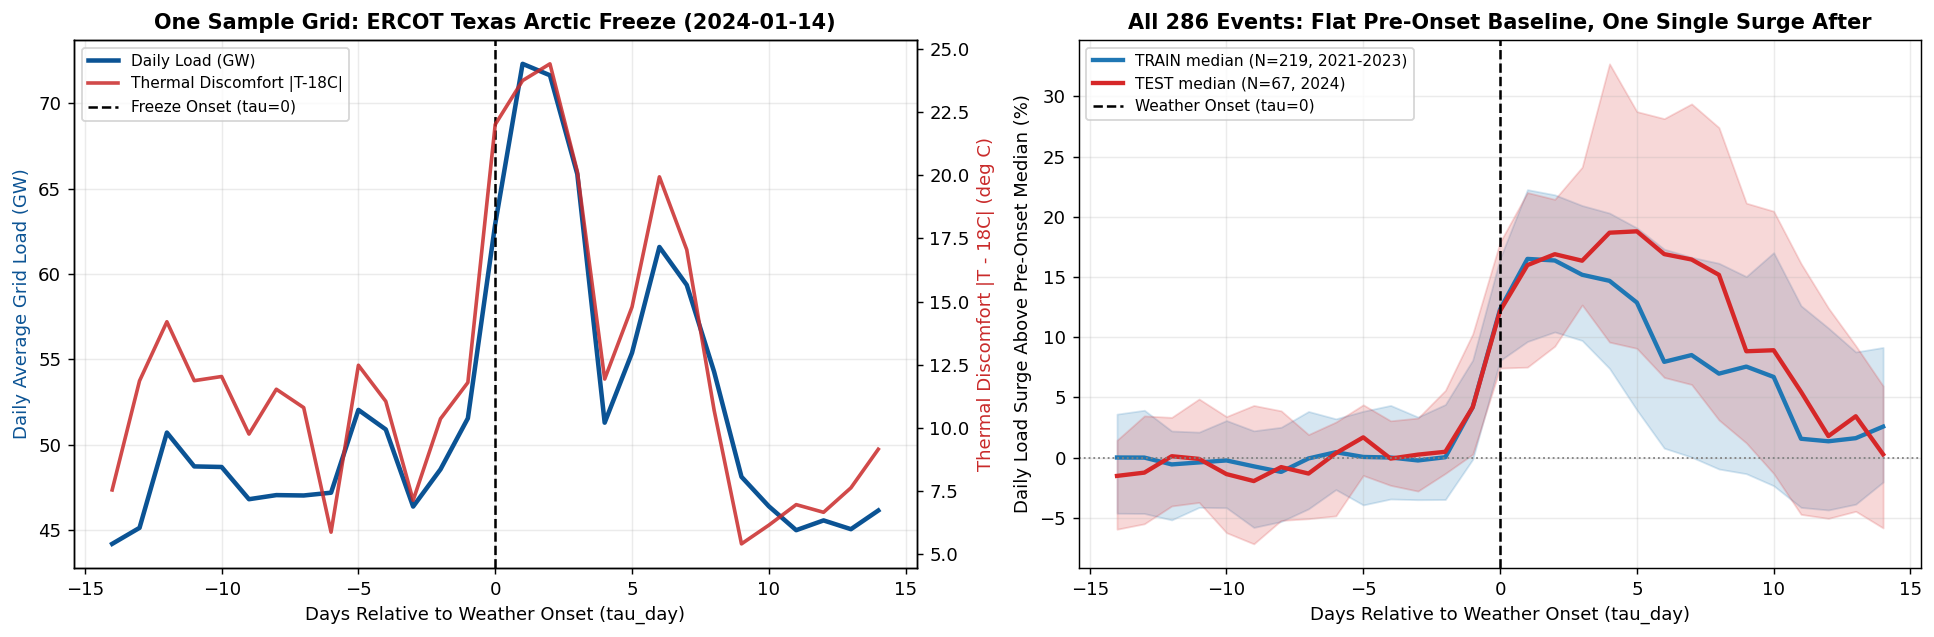

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=130)

# --- Left Panel: One Sample Event (ERCOT Texas Freeze — Jan 2024, Test Split) ---
ex_row = meta[(meta['ba'] == 'ERCO') & (meta['split'] == 'test')].iloc[0]
ex = simple_df[simple_df['sample_id'] == ex_row['sample_id']].sort_values('tau_day')
ax1 = axes[0]
ax1_r = ax1.twinx()

l1, = ax1.plot(ex['tau_day'], ex['load_mw'] / 1000.0, color='#0b5394', lw=2.5, label='Daily Load (GW)')
l2, = ax1_r.plot(ex['tau_day'], ex['thermal_discomfort_c'], color='#c92a2a', lw=2.0, alpha=0.85, label='Thermal Discomfort |T-18C|')
v1 = ax1.axvline(0, color='black', ls='--', lw=1.4, label='Freeze Onset (tau=0)')

ax1.set_title(f'One Sample Grid: ERCOT Texas Arctic Freeze ({ex_row["onset_date"]})', fontsize=11.5, fontweight='bold')
ax1.set_xlabel('Days Relative to Weather Onset (tau_day)')
ax1.set_ylabel('Daily Average Grid Load (GW)', color='#0b5394')
ax1_r.set_ylabel('Thermal Discomfort |T - 18C| (deg C)', color='#c92a2a')
ax1.grid(True, alpha=0.25)
ax1.legend([l1, l2, v1], [l1.get_label(), l2.get_label(), v1.get_label()], loc='upper left', fontsize=8.5)

# --- Right Panel: All 286 Single-Surge Events — Clean % Surge Above Pre-Onset Median ---
pre_med = simple_df[simple_df['tau_day'] < 0].groupby('sample_id')['load_mw'].median().rename('pre_med')
df_rel = simple_df.merge(pre_med, on='sample_id')
df_rel['surge_pct'] = (df_rel['load_mw'] / df_rel['pre_med'] - 1.0) * 100.0

ax2 = axes[1]
n_tr = meta[meta['split'] == 'train'].shape[0]
n_te = meta[meta['split'] == 'test'].shape[0]
for split_name, color, label in [('train', '#1f77b4', f'TRAIN median (N={n_tr}, 2021-2023)'),
                                 ('test', '#d62728', f'TEST median (N={n_te}, 2024)')]:
    sub = df_rel[df_rel['split'] == split_name]
    stats = sub.groupby('tau_day')['surge_pct'].agg(
        med='median',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75),
    ).reset_index()
    ax2.plot(stats['tau_day'], stats['med'], color=color, lw=2.4, label=label)
    ax2.fill_between(stats['tau_day'], stats['q25'], stats['q75'], color=color, alpha=0.18)

ax2.axhline(0, color='gray', ls=':', lw=1.0)
ax2.axvline(0, color='black', ls='--', lw=1.4, label='Weather Onset (tau=0)')
ax2.set_title(f'All {len(meta)} Events: Flat Pre-Onset Baseline, One Single Surge After', fontsize=11.5, fontweight='bold')
ax2.set_xlabel('Days Relative to Weather Onset (tau_day)')
ax2.set_ylabel('Daily Load Surge Above Pre-Onset Median (%)')
ax2.grid(True, alpha=0.25)
ax2.legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.savefig('data/power_grid_simple_overview.png', dpi=150, bbox_inches='tight')
plt.show()